# Workshop 1 | Online Retail, December 2010–November 2011

**Moisés Medina and Ignacia Castillo** · Business Intelligence IIB423T-1 · 25 September 2026

This is our first inspection of two possible C1 directions. The input is a date-filtered, otherwise uncleaned extract of the [UCI Online Retail dataset](https://archive.ics.uci.edu/dataset/352/online+retail). One row is a recorded invoice line, not an entire order or a customer. Values are in GBP. The CSV in `../data/` makes this notebook run after extracting the submission archive. AI assisted with drafting Python code; the team is responsible for the research choices and interpretation. See the report's Process record for limitations.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display
from retail_analysis import load_case, write_outputs

ROOT = Path.cwd().resolve()
if ROOT.name == 'analysis':
    ROOT = ROOT.parent
DATA = ROOT / 'data'
FIGURES = ROOT / 'analysis' / 'figures'
df = load_case(DATA / 'online_retail_2010dec_2011nov_input.csv')
print('Rows, columns:', df.shape)
display(df.head(5))

Rows, columns: (516384, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


## 1. Scope and quality

We retain all eight UCI source columns and every row dated from 1 December 2010 through 30 November 2011. This gives 12 complete months. December 2011 ends on the ninth in the source, so it is not included in month comparisons. The checks below flag missing identifiers, missing descriptions, repeated identical rows, non-positive prices and special stock codes. We keep these rows in the input and apply explicit eligibility rules only when calculating each measure.

In [2]:
info, monthly_sales, monthly_cancel, products, countries, customers = write_outputs(df, DATA, FIGURES)
display(pd.DataFrame([info]).T.rename(columns={0: 'observed value'}))

,observed value
rows,516384
min_date,2010-12-01 08:26:00
max_date,2011-11-30 17:42:00
invoices,24885
countries,38
stock_codes,4067
missing_customer_id,127216
missing_description,1439
exact_duplicate_rows,4989
zero_or_negative_price,2463


These quality checks can overlap; they are not a row-flow subtraction. We retain all rows in the input and apply exclusions only to a defined measure.

- **Customer ID:** A blank ID cannot be assigned to a person. We keep its purchase line in overall value and monthly context, but exclude it from customer ranking. Grouping all blank IDs as one customer would invent an account. Among eligible positive purchase lines, 121,721 have no ID; known IDs account for 85.7% of eligible value.
- **Description and duplicates:** A missing description does not remove quantity, price or stock code, so we keep it and use the code as a provisional product key. We also retain exact repeats because there is no line ID to distinguish an error from separate identical items; the report gives a deduplication sensitivity check.
- **Price:** The 2,463 non-positive-price rows comprise 2,461 recorded zeros and two negative-price bad-debt adjustments. A zero might reflect a gift, promotion, administrative entry or missing price, but there is no coupon field to verify why. We do not impute another order's price or a monthly product average because that would invent this transaction's charge. They remain in the input and are excluded from the priced-event measures.
- **Stock code and invoice flag:** The provisional five-digit merchandise pattern makes a comparable, reproducible scope for both candidates. Codes outside it include service/adjustment entries and product-like variants, so this boundary needs sensitivity testing. A `C` prefix is UCI's cancellation flag; it excludes a line from positive purchase value and is assessed under Candidate B's eligibility rules. A negative quantity without `C` is not automatically a confirmed customer cancellation.

Our business use is a retrospective customer portfolio review for A and a cancellation-process review for B. `Quantity × UnitPrice` on positive priced lines is observed line value, not profit or reconciled revenue; the dataset has no costs, payment reconciliation or promotion exposure.

## 2. Candidate A — customer concentration in purchase value

**Question:** How concentrated is *observed purchase-line value* among customers with an ID, and how does the contribution of customers observed in one invoice differ from that of others? A commercial analyst could use this to decide which customer groups deserve closer study. We include a row when its stock code follows the provisional five-digit merchandise pattern, its invoice does not start with `C`, and both quantity and unit price are positive. Line value is `Quantity × UnitPrice`. We then group by non-missing `CustomerID`. This is not profit, lifetime value, or a measure of all customers: missing IDs are excluded and the file covers only one year.

,Measure,Value
0,Customers with ID,4293.0
1,Known-ID share of observed purchase value,85.7
2,Top 1% customer share of known-ID value,30.9
3,Top 10% customer share of known-ID value,60.5
4,Customers observed in one invoice,1551.0
5,Their share of known-ID value,7.8


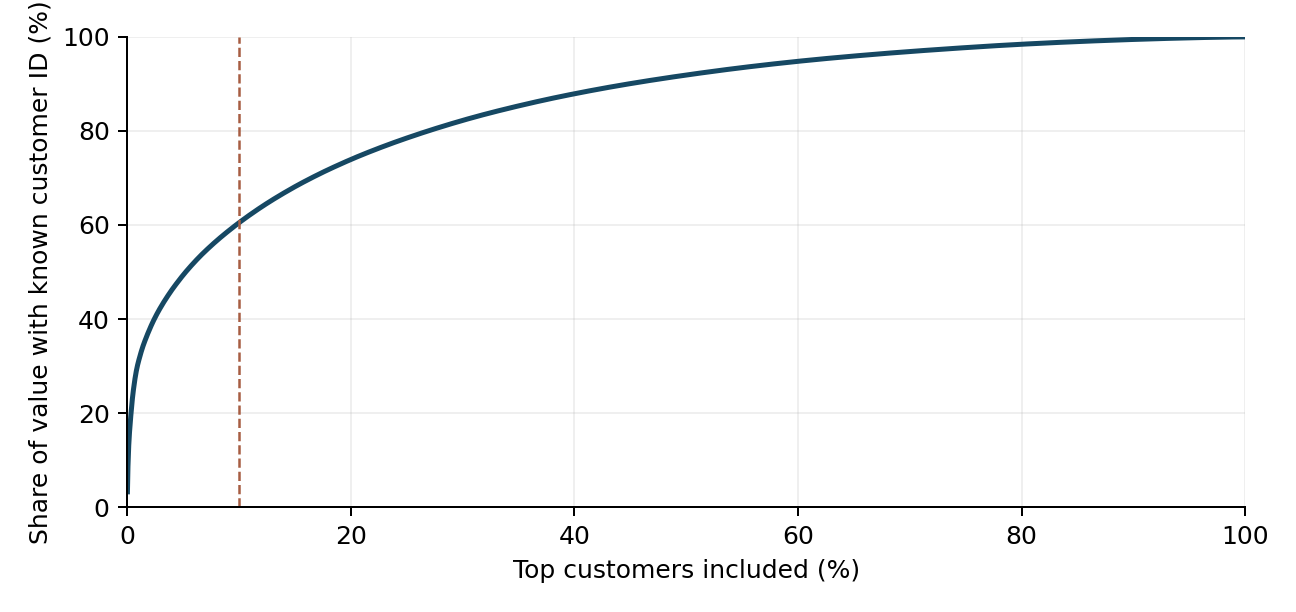

,month,lines,invoices,units,observed_value_gbp
0,2010-12,41041,1548,357523,770510.16
1,2011-01,34012,1080,387029,669871.64
2,2011-02,26757,1093,282794,506167.81
3,2011-03,35406,1440,376586,688241.68
4,2011-04,28821,1235,308141,513866.58
5,2011-05,35781,1668,394806,737411.85
6,2011-06,35588,1525,388397,736055.65
7,2011-07,38295,1451,400621,685260.50
8,2011-08,34210,1339,420928,722585.61
9,2011-09,48903,1818,569391,1027021.96


,StockCode,description,lines,observed_value_gbp
0,22423,REGENCY CAKESTAND 3 TIER,1955,168477.87
1,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2198,102292.39
2,47566,PARTY BUNTING,1678,98585.85
3,85099B,JUMBO BAG RED RETROSPOT,2058,92113.15
4,23166,MEDIUM CERAMIC TOP STORAGE JAR,236,81448.21
5,22086,PAPER CHAIN KIT 50'S CHRISTMAS,1079,58081.58
6,23084,RABBIT NIGHT LIGHT,900,57321.97
7,84879,ASSORTED COLOUR BIRD ORNAMENT,1442,56932.19
8,79321,CHILLI LIGHTS,639,51478.02
9,22502,PICNIC BASKET WICKER SMALL,469,51426.62


,Country,purchase_lines,observed_value_gbp,cancel_lines,cancel_line_share_pct
0,United Kingdom,458301,8132965.10,7090.0,1.52
1,Germany,8342,197445.47,414.0,4.73
2,France,7774,177383.37,122.0,1.55
3,EIRE,7438,263612.86,289.0,3.74
4,Spain,2358,55436.90,39.0,1.63
5,Netherlands,2236,272161.32,4.0,0.18
6,Switzerland,1933,53016.50,33.0,1.68
7,Belgium,1842,35567.21,32.0,1.71


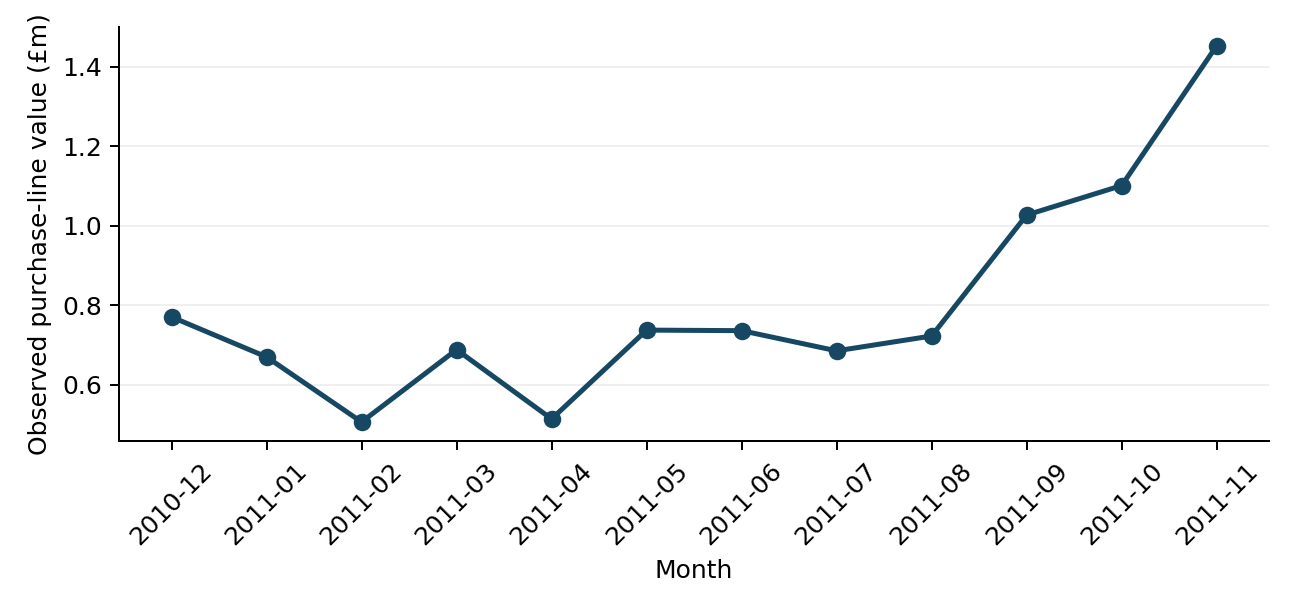

In [3]:
display(pd.DataFrame({
    'Measure': ['Customers with ID', 'Known-ID share of observed purchase value',
                'Top 1% customer share of known-ID value', 'Top 10% customer share of known-ID value',
                'Customers observed in one invoice', 'Their share of known-ID value'],
    'Value': [info['known_customers'], round(info['known_customer_id_value_share_pct'], 1),
              round(info['top_1pct_customer_value_share_pct'], 1),
              round(info['top_10pct_customer_value_share_pct'], 1),
              info['one_invoice_customers'], round(info['one_invoice_customer_value_share_pct'], 1)]
}))
display(__import__('IPython').display.Image(filename=str(FIGURES / 'customer_concentration.png')))
display(monthly_sales.round(2))
display(products.head(10).round(2))
display(countries.head(8).round(2))
display(__import__('IPython').display.Image(filename=str(FIGURES / 'monthly_purchase_value.png')))

The top 10% of identifiable customers account for 60.5% of value within the known-ID subset; the top 1% account for 30.9%. Customers observed in only one invoice make up 36.1% of identifiable customers but 7.8% of their value. This supports examining concentration and repeat purchasing, but it does not establish loyalty or lifetime value. Customer IDs are missing on many lines, and the observation window may cut off earlier or later purchases. Monthly value is context: February 2011 is lowest and November highest, but a single annual cycle cannot establish a Christmas effect.

## 3. Candidate B — cancellation invoice patterns

**Question:** In which months and customer countries are cancellation invoice lines most visible? An operations analyst could prioritise a review of cancellation reasons and handling. We count merchandise rows with a `C` invoice, negative quantity and positive unit price. The monthly share uses **distinct eligible cancellation invoices divided by distinct eligible purchase plus cancellation invoices**. This is an event mix in the observed window, *not* the probability that a purchase was later cancelled: the source does not link a cancellation to its original invoice.

,month,purchase_lines,purchase_invoices,cancel_lines,cancel_invoices,cancel_units,cancel_invoice_share_pct,cancel_line_share_pct
0,2010-12,41041,1548,697,301,16003,16.28,1.67
1,2011-01,34012,1080,679,247,79784,18.61,1.96
2,2011-02,26757,1093,418,191,2606,14.88,1.54
3,2011-03,35406,1440,642,281,4338,16.33,1.78
4,2011-04,28821,1235,530,220,13598,15.12,1.81
5,2011-05,35781,1668,558,267,4057,13.80,1.54
6,2011-06,35588,1525,668,298,7214,16.35,1.84
7,2011-07,38295,1451,641,235,5826,13.94,1.65
8,2011-08,34210,1339,616,240,11661,15.20,1.77
9,2011-09,48903,1818,760,299,7084,14.12,1.53


,Country,purchase_lines,cancel_lines,cancel_line_share_pct
0,United Kingdom,458301,7090.0,1.52
1,Germany,8342,414.0,4.73
2,France,7774,122.0,1.55
3,EIRE,7438,289.0,3.74
4,Spain,2358,39.0,1.63
5,Netherlands,2236,4.0,0.18
6,Switzerland,1933,33.0,1.68
7,Belgium,1842,32.0,1.71
8,Portugal,1367,10.0,0.73
9,Australia,1180,73.0,5.83


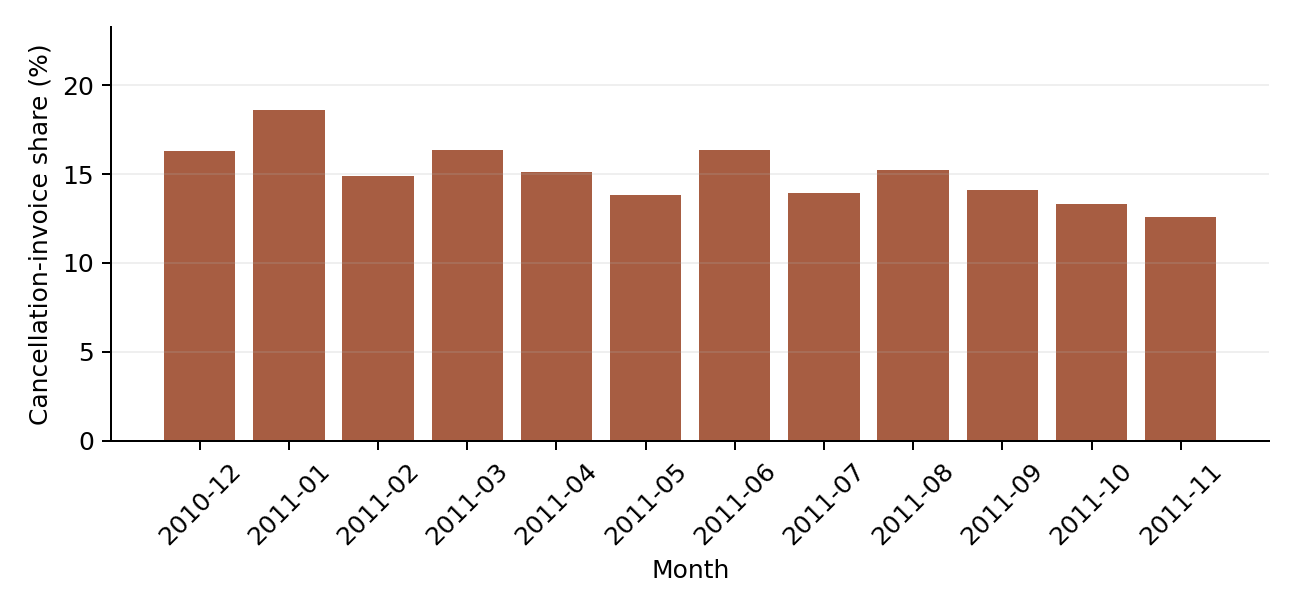

In [4]:
display(monthly_cancel.round(2))
display(countries.loc[countries.purchase_lines >= 1000, ['Country', 'purchase_lines', 'cancel_lines', 'cancel_line_share_pct']].round(2))
display(__import__('IPython').display.Image(filename=str(FIGURES / 'monthly_cancellation_share.png')))

The cancellation invoice share is highest in January 2011 (about 18.6%) and lowest in November 2011 (about 12.6%). Germany and EIRE show higher cancellation-line shares than the United Kingdom among countries with at least 1,000 positive merchandise lines. Country is recorded as the customer's country, not necessarily the shipment destination. The period may omit the purchases associated with cancellations; no causal or product-quality claim follows from these shares.

## 4. Comparison and next decision

Candidate A has a direct value measure and a nontrivial customer-concentration question, but missing customer IDs and the finite observation window limit interpretation. Candidate B addresses a different operational question, but it cannot yet support a genuine purchase-level cancellation rate. We provisionally prefer A for C1 and ask the instructor whether B's descriptive cancellation mix is still a sufficiently useful second direction. Future ML could explore customer segments if ID coverage and timing are adequate; B would need a purchase–cancellation link and reason codes before predictive work. A dashboard could display contribution by customer group, observed invoice frequency and missing-ID coverage; B could show cancellation counts with denominators and data-quality flags.